#### Read in data

In [51]:
import os
from tqdm import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_context("talk", font_scale=1.35)

In [14]:
cell_type = "B_Memory"
singe_cell_gene_peak_link_dir = f"/data_vol/FINAL/GenePeak/scMultiMap/L2/{cell_type}"
eqtl_dir = f"/data_vol/FINAL/QTL/rna/L2_manual/{cell_type}"
caqtl_dir = f"/data_vol/FINAL/QTL/atac/permissive/L2_manual/{cell_type}"
out_dir = "/data_vol/analysis_outputs/QTL_analysis/chromatin_priming"

In [ ]:
# read in sc gene peak links
sc_gene_peak_links = []
for chr in tqdm(range(1, 23)):
    sc_gene_peak_links.append(pd.read_csv(f"{singe_cell_gene_peak_link_dir}/{cell_type}_chr{chr}_scMultiMap_nCell_10000.csv.gz"))
sc_gene_peak_links = pd.concat(sc_gene_peak_links)

# make sure peak names are formatted to match QTL dataframe
sc_gene_peak_links["peak"] = sc_gene_peak_links["peak"].apply(lambda x: x.replace("-", ":", 1))

if not os.path.exists(f"{out_dir}/{cell_type}_chr1_rna_atac_qtls_gene_peak_links_merged.txt"):
    ## RNA
    all_pairs_rna = pd.read_parquet(f"{eqtl_dir}/{cell_type}.cis_qtl_pairs.1.parquet")
    egenes = pd.read_csv(f"{eqtl_dir}/{cell_type}.cis_qtl_egene.1.txt", sep="\t")
    all_pairs_rna = all_pairs_rna.merge(egenes[["phenotype_id", "qval", "pval_nominal_threshold"]], on="phenotype_id", how="left")
    all_pairs_rna["Significant"] = False
    all_pairs_rna.loc[(all_pairs_rna["qval"] < 0.05) & (all_pairs_rna["pval_nominal"] < all_pairs_rna["pval_nominal_threshold"]), "Significant"] = True

    # only keep most significant association for each variant
    all_pairs_rna = all_pairs_rna.sort_values(by="pval_nominal").drop_duplicates(subset="variant_id")

    ## ATAC
    all_pairs_atac = pd.read_parquet(f"{caqtl_dir}/{cell_type}.cis_qtl_pairs.1.parquet")
    apeaks = pd.read_csv(f"{caqtl_dir}/{cell_type}.cis_qtl_egene.1.txt", sep="\t")
    all_pairs_atac = all_pairs_atac.merge(apeaks[["phenotype_id", "qval", "pval_nominal_threshold"]], on="phenotype_id", how="left")
    all_pairs_atac["Significant"] = False
    all_pairs_atac.loc[(all_pairs_atac["qval"] < 0.05) & (all_pairs_atac["pval_nominal"] < all_pairs_atac["pval_nominal_threshold"]), "Significant"] = True

    # only keep most significant association for each variant
    all_pairs_atac = all_pairs_atac.sort_values(by="pval_nominal").drop_duplicates(subset="variant_id")

    # merge RNA and ATAC QTLs
    all_pairs = all_pairs_rna.merge(all_pairs_atac, on=["variant_id"], 
                how="inner", suffixes=("_eqtl", "_caqtl"))
    
    # merge sc gene peak links with qtls
    all_pairs = all_pairs.merge(sc_gene_peak_links, left_on=["phenotype_id_eqtl", "phenotype_id_caqtl"], right_on=["gene", "peak"], how="inner")
    all_pairs["|cor|"] = all_pairs["cor"].abs()

    # annotate with pLI
    gene_annots = pd.read_csv("/data_vol/analysis_outputs/QTL_analysis/qtl_properties_mostafavi/gwas_eqtl/gene_annots/pc_genes.txt", sep="\t")[["GeneSymbol", "pLI"]]
    all_pairs = all_pairs.merge(gene_annots, left_on="phenotype_id_eqtl", right_on="GeneSymbol", how="left")

    # annotate based on qtl significance
    all_pairs["Variant category"] = "Not significant"
    all_pairs.loc[(all_pairs["Significant_caqtl"] == True) & (all_pairs["Significant_eqtl"] == False), "Variant category"] = "caQTL only"
    all_pairs.loc[(all_pairs["Significant_caqtl"] == False) & (all_pairs["Significant_eqtl"] == True), "Variant category"] = "eQTL only"
    all_pairs.loc[(all_pairs["Significant_caqtl"] == True) & (all_pairs["Significant_eqtl"] == True), "Variant category"] = "Both significant"

    all_pairs["-log10 gene-peak link p-value"] = -np.log10(all_pairs["pval"])
    all_pairs.to_csv(f"{out_dir}/{cell_type}_chr1_rna_atac_qtls_gene_peak_links_merged.txt", 
                    index=False, sep="\t")
    
else:
    all_pairs = pd.read_csv(f"{out_dir}/{cell_type}_chr1_rna_atac_qtls_gene_peak_links_merged.txt", sep="\t")


#### Compare caQTL and eQTL effect sizes

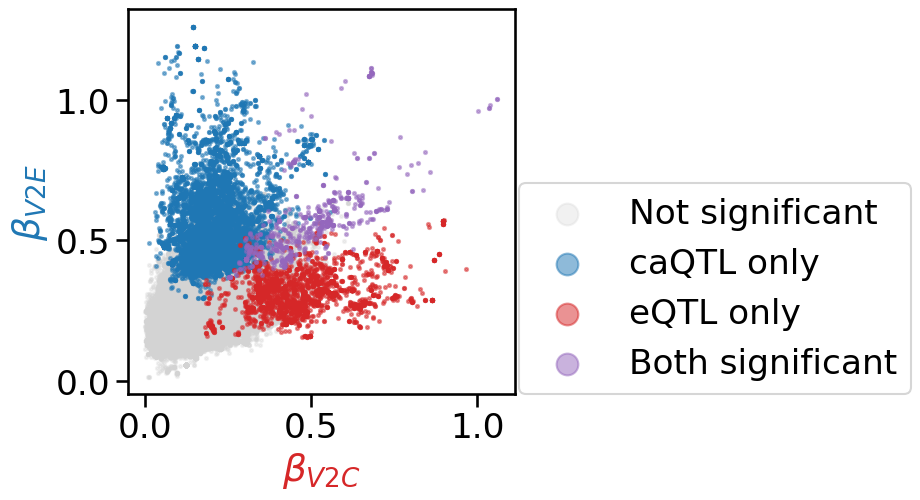

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
plt.scatter(all_pairs[(all_pairs["Significant_caqtl"] == False) & (all_pairs["Significant_eqtl"] == False)]["slope_eqtl"].abs(), 
            all_pairs[(all_pairs["Significant_caqtl"] == False) & (all_pairs["Significant_eqtl"] == False)]["slope_caqtl"].abs(), 
            color="lightgray", s=5, alpha=0.3, label="Not significant")
plt.scatter(all_pairs[(all_pairs["Significant_caqtl"] == True) & (all_pairs["Significant_eqtl"] == False)]["slope_eqtl"].abs(), 
            all_pairs[(all_pairs["Significant_caqtl"] == True) & (all_pairs["Significant_eqtl"] == False)]["slope_caqtl"].abs(), 
            color="tab:blue", s=5, alpha=0.5, label="caQTL only")
plt.scatter(all_pairs[(all_pairs["Significant_caqtl"] == False) & (all_pairs["Significant_eqtl"] == True)]["slope_eqtl"].abs(), 
            all_pairs[(all_pairs["Significant_caqtl"] == False) & (all_pairs["Significant_eqtl"] == True)]["slope_caqtl"].abs(), 
            color="tab:red", s=5, alpha=0.5, label="eQTL only")
plt.scatter(all_pairs[(all_pairs["Significant_caqtl"] == True) & (all_pairs["Significant_eqtl"] == True)]["slope_eqtl"].abs(), 
            all_pairs[(all_pairs["Significant_caqtl"] == True) & (all_pairs["Significant_eqtl"] == True)]["slope_caqtl"].abs(), 
            color="tab:purple", s=5, alpha=0.5, label="Both significant")
plt.xlabel("$\\beta_{V2E}$", color="tab:red")
plt.ylabel("$\\beta_{V2C}$", color="tab:blue")
plt.legend(loc=(1.01, 0), markerscale=7)
plt.savefig(f"{out_dir}/eqtl_vs_caqtl_effect_size_scatter.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{out_dir}/eqtl_vs_caqtl_effect_size_scatter.pdf", dpi=300, bbox_inches="tight")

#### Compare gene-peak correlations for caQTLs vs eQTLs

/tmp/ipykernel_5143/1929245012.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=all_pairs, x="Variant category", y="|cor|",
/tmp/ipykernel_5143/1929245012.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([o.replace(" ", "\n") for o in order])


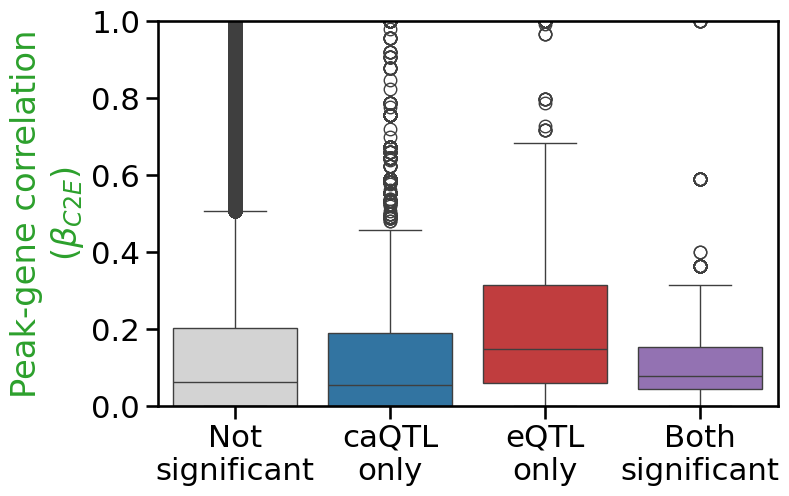

In [48]:
fig, ax = plt.subplots(1, 1, figsize=(8, 5))

order = ["Not significant", "caQTL only", "eQTL only", "Both significant"]
sns.boxplot(data=all_pairs, x="Variant category", y="|cor|",
            order=order, 
            palette=["lightgray", "tab:blue", "tab:red", "tab:purple"])
plt.ylim(0, 1)
plt.ylabel("Peak-gene correlation\n($\\beta_{C2E}$)", color="tab:green")
plt.xlabel("")
ax.set_xticklabels([o.replace(" ", "\n") for o in order])

plt.savefig(f"{out_dir}/gene_peak_link_correlation_for_qtl_types_boxplot.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{out_dir}/gene_peak_link_correlation_for_qtl_types_boxplot.pdf", dpi=300, bbox_inches="tight")

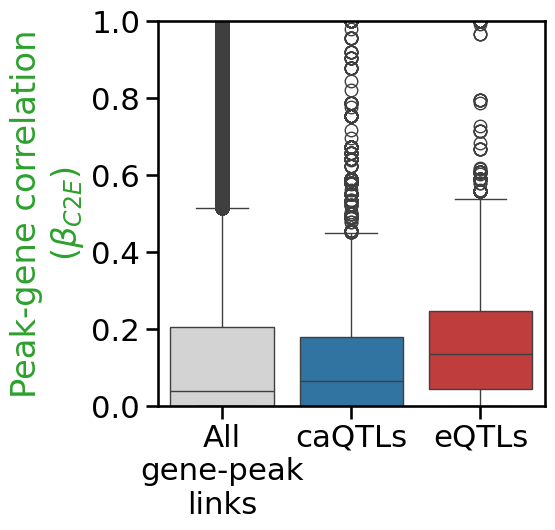

In [49]:
sc_gene_peak_links["|cor|"] = sc_gene_peak_links["cor"].abs()

fig, ax = plt.subplots(1, 1, figsize=(5, 5))

plot_col = "|cor|"
sns.boxplot(data={"All\ngene-peak\nlinks": sc_gene_peak_links[plot_col].sample(500_000, replace=False).values,
                  "caQTLs": all_pairs.loc[all_pairs["Significant_caqtl"] == True, plot_col].values, 
                  "eQTLs": all_pairs.loc[all_pairs["Significant_eqtl"] == True, plot_col].values},
                  palette=["lightgray", "tab:blue", "tab:red"])
ax.set_ylim(0, 1)
ax.set_ylabel("Peak-gene correlation\n($\\beta_{C2E}$)", color="tab:green")
ax.set_xlabel("")

plt.savefig(f"{out_dir}/gene_peak_link_correlation_for_qtl_types_all_pairs_boxplot.png", dpi=300, bbox_inches="tight")
plt.savefig(f"{out_dir}/gene_peak_link_correlation_for_qtl_types_all_pairs_boxplot.pdf", dpi=300, bbox_inches="tight")

#### Compare cell type sharing between modalities

In [52]:
eqtl_dir = "/data_vol/FINAL/QTL/rna/L2_manual"
caqtl_dir = "/data_vol/FINAL/QTL/atac/permissive/L2_manual"

cell_types = [d for d in os.listdir(eqtl_dir) if os.path.isdir(f"{eqtl_dir}/{d}")]

In [ ]:
# Read in cell type specific QTLs and count number of cell types each variant is detected in

qtls = {}
for c in tqdm(cell_types):
    eqtls = pd.read_csv(f"{eqtl_dir}/{c}/{c}.cis_qtl_snp.all_significant.annot.txt", sep="\t").dropna(subset=["ICC_AF"])
    eqtls.sort_values(by=["ICC_AF"], ascending=False, inplace=True)
    eqtls = eqtls.loc[eqtls["ICC_AF"] >= 0.1]
    eqtls.drop_duplicates(subset=["variant_id", "phenotype_id"], inplace=True)
    eqtls["cell_type"] = c
    caqtls = pd.read_csv(f"{caqtl_dir}/{c}/{c}.cis_qtl_snp.all_significant.annot.txt", sep="\t").dropna(subset=["ICC_AF"])
    caqtls = caqtls.loc[caqtls["ICC_AF"] >= 0.1]
    caqtls.drop_duplicates(subset=["variant_id", "phenotype_id"], inplace=True)
    caqtls["cell_type"] = c

    assert eqtls[["variant_id", "phenotype_id"]].value_counts().max() == 1
    assert caqtls[["variant_id", "phenotype_id"]].value_counts().max() == 1

    qtls[c] = {"eqtls": eqtls, "caqtls": caqtls}

all_eqtls = pd.concat([qtls[c]["eqtls"] for c in qtls.keys()])
all_caqtls = pd.concat([qtls[c]["caqtls"] for c in qtls.keys()])

100%|██████████| 13/13 [00:25<00:00,  1.93s/it]


In [54]:
all_eqtls_grouped_with_cell_types = all_eqtls.groupby(["variant_id", "phenotype_id"])["cell_type"].unique().reset_index()
all_eqtls_grouped_with_cell_types["count"] = all_eqtls_grouped_with_cell_types["cell_type"].apply(lambda x: len(x))
all_eqtls_grouped_with_cell_types = all_eqtls_grouped_with_cell_types.sort_values(by="count", ascending=False).drop_duplicates(subset=["variant_id"])

all_caqtls_grouped_with_cell_types = all_caqtls.groupby(["variant_id", "phenotype_id"])["cell_type"].unique().reset_index()
all_caqtls_grouped_with_cell_types["count"] = all_caqtls_grouped_with_cell_types["cell_type"].apply(lambda x: len(x))
all_caqtls_grouped_with_cell_types = all_caqtls_grouped_with_cell_types.sort_values(by="count", ascending=False).drop_duplicates(subset=["variant_id"])

qtl_counts_combined_with_cell_types = all_eqtls_grouped_with_cell_types.merge(all_caqtls_grouped_with_cell_types, on="variant_id", how="inner", suffixes=("_eqtl", "_caqtl"))
qtl_counts_combined_with_cell_types["count_shared_cell_types"] = qtl_counts_combined_with_cell_types.apply(lambda row: len(list(set(row["cell_type_eqtl"]) & 
                                                                                                                                set(row["cell_type_caqtl"]))), axis=1)

In [55]:
# read in GWAS data
data_dir = "/data_vol/References/GWAS/PriceLab/hg38"
immune_traits = ["Celiac", "IBD_deLange2017",
                 "Rheumatoid_Arthritis", "Crohns_Disease",
                 "Lupus", "Primary_biliary_cirrhosis", "Ulcerative_Colitis"]

gwas_sumstats = {}
for trait in tqdm(immune_traits):
    gwas_sumstats[trait]  = []
    for chr in range(1, 23):
        gwas_file = f"{data_dir}/{trait}_chr{chr}_hg38.sumstats.gz"
        chr_df = pd.read_csv(gwas_file, sep="\t")
        chr_df = chr_df[chr_df["Z"].abs() > 5.45]  # 5e-8 significance threshold
        gwas_sumstats[trait].append(chr_df)
    gwas_sumstats[trait] = pd.concat(gwas_sumstats[trait])

    significant_gwas_variants = pd.concat(gwas_sumstats.values())
    significant_gwas_variants = significant_gwas_variants.drop_duplicates(subset=["SNP"])

100%|██████████| 7/7 [00:20<00:00,  2.92s/it]


In [56]:
# Annotate QTLs overlapping GWAS hits
qtl_counts_combined_with_cell_types["Significant GWAS variant"] = False
qtl_counts_combined_with_cell_types.loc[qtl_counts_combined_with_cell_types["variant_id"].isin(significant_gwas_variants["SNP"]), "Significant GWAS variant"] = True

<Figure size 640x480 with 0 Axes>

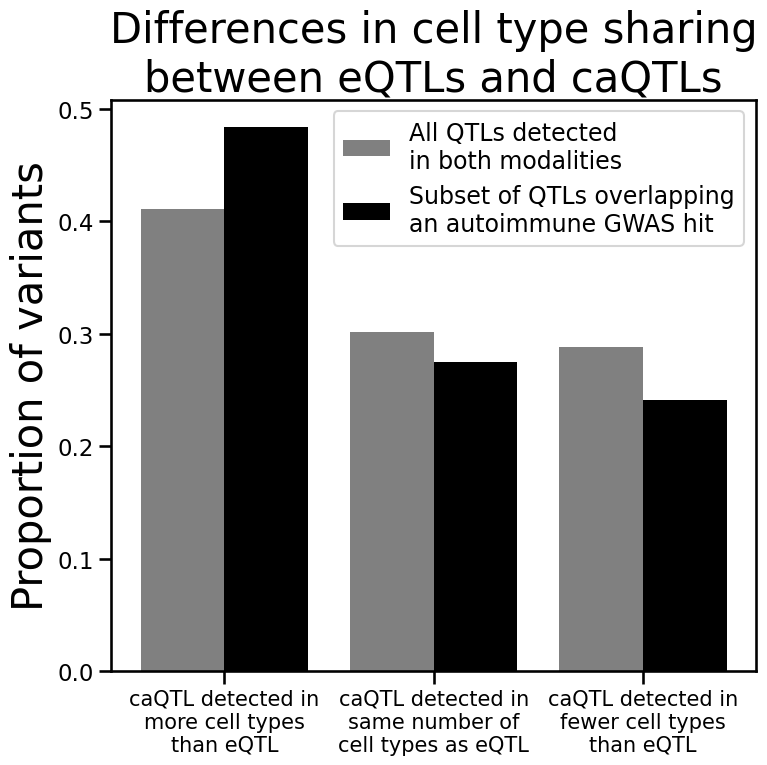

In [74]:
sns.set_context("talk", font_scale=1)
plt.clf()
fig, ax = plt.subplots(1, 1, figsize=(8, 8))
width = 0.4

# All shared QTLs
tmp_df = qtl_counts_combined_with_cell_types[(qtl_counts_combined_with_cell_types["count_eqtl"] > 0) & 
                            (qtl_counts_combined_with_cell_types["count_caqtl"] > 0)]
proportions = [len(tmp_df[(tmp_df["count_caqtl"] > tmp_df["count_eqtl"])])/len(tmp_df),
               len(tmp_df[(tmp_df["count_caqtl"] == tmp_df["count_eqtl"])])/len(tmp_df),
               len(tmp_df[(tmp_df["count_caqtl"] < tmp_df["count_eqtl"])])/len(tmp_df)]
plt.bar(np.arange(0, 3), proportions, width=width, color="gray",
        label="All QTLs detected\nin both modalities")

# Shared QTLs overlapping significant GWAS variant
tmp_df = qtl_counts_combined_with_cell_types[(qtl_counts_combined_with_cell_types["Significant GWAS variant"] == True) &
                                             (qtl_counts_combined_with_cell_types["count_eqtl"] > 0) & 
                                             (qtl_counts_combined_with_cell_types["count_caqtl"] > 0)]

proportions = [len(tmp_df[(tmp_df["count_caqtl"] > tmp_df["count_eqtl"])])/len(tmp_df),
               len(tmp_df[(tmp_df["count_caqtl"] == tmp_df["count_eqtl"])])/len(tmp_df),
               len(tmp_df[(tmp_df["count_caqtl"] < tmp_df["count_eqtl"])])/len(tmp_df)]
plt.bar(np.arange(0, 3)+width, proportions, width=width, color="black",
        label="Subset of QTLs overlapping\nan autoimmune GWAS hit")

plt.xticks(np.arange(0, 3)+width/2, 
           ["caQTL detected in\nmore cell types\nthan eQTL", 
            "caQTL detected in\nsame number of\ncell types as eQTL", 
            "caQTL detected in\nfewer cell types\nthan eQTL"], fontsize=15)
plt.ylabel("Proportion of variants", fontsize=30)
plt.title("Differences in cell type sharing\nbetween eQTLs and caQTLs", fontsize=30)
plt.legend(fontsize=17)
plt.tight_layout()
plt.savefig(f"{out_dir}/cell_type_sharing_differences_with_gwas.png", dpi=300)
plt.savefig(f"{out_dir}/cell_type_sharing_differences_with_gwas.pdf", dpi=300)